# k-NN V6

For this experiment, I wanted to see if using more training samples would improve the accuracy. I tested 1000, 2000, 4000 and 8000 samples while keeping the same k values and distance function.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys

import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data_loader import load_task, split_train_val
from src.models.knn import KNNClassifier, euclidean_distance

image_k = 1
sentiment_k = 3
training_sizes = [1000, 2000, 4000, 8000]


I started by testing the different training sizes on the image dataset.

In [2]:
X, y, image_X_test, image_test_ids = load_task("image")
image_X_train, X_val, image_y_train, y_val = split_train_val(
    X, y, val_fraction=0.2, seed=42
)
image_X_val = X_val[:200]
image_y_val = y_val[:200]
assert len(image_X_train) >= max(training_sizes)

result_dir = project_root / "results" / "image"
v5_validation = pd.read_csv(result_dir / "knn_v5_validation.csv")
v5_summary = pd.read_csv(result_dir / "knn_v5_summary.csv")
assert v5_validation["validation_index"].tolist() == list(range(200))
assert v5_validation["actual_label"].tolist() == image_y_val.tolist()

image_rows = []
image_validation_predictions = {}
image_best_accuracy = -1
print("Image: k=" + str(image_k) + ", 200 validation samples")
for training_size in training_sizes:
    train_features = image_X_train[:training_size]
    train_labels = image_y_train[:training_size]
    clf = KNNClassifier(k=image_k, distance_fn=euclidean_distance, voting_method="majority")
    clf.fit(train_features, train_labels)
    start = perf_counter()
    y_pred = clf.predict(image_X_val)
    prediction_time = perf_counter() - start
    accuracy = sum(p == t for p, t in zip(y_pred, image_y_val)) / len(image_y_val)
    image_validation_predictions[training_size] = y_pred
    image_rows.append({
        "dataset": "image",
        "version": "V6",
        "k": image_k,
        "distance_metric": "euclidean",
        "voting_method": "majority",
        "normalized": False,
        "training_samples": len(train_features),
        "validation_samples": len(image_X_val),
        "validation_accuracy": accuracy,
        "prediction_time_seconds": prediction_time,
    })
    print(f"Training samples={training_size:4d}  accuracy={accuracy:.2%}  prediction time={prediction_time:.6f} s")

    # Sizes are ascending, so the smaller size wins an accuracy tie.
    if accuracy > image_best_accuracy:
        image_best_size = training_size
        image_best_accuracy = accuracy
    if training_size == 1000:
        assert accuracy == 0.215
        assert accuracy == v5_summary.loc[v5_summary["voting_method"] == "majority", "validation_accuracy"].iloc[0]
        assert y_pred == v5_validation["predicted_label"].tolist()

image_summary = pd.DataFrame(image_rows)
image_summary.to_csv(result_dir / "knn_v6_summary.csv", index=False)
pd.DataFrame({
    "validation_index": range(len(image_y_val)),
    "actual_label": image_y_val,
    "predicted_label": image_validation_predictions[image_best_size],
}).to_csv(result_dir / "knn_v6_validation.csv", index=False)
print(f"Selected training size: {image_best_size}, accuracy={image_best_accuracy:.2%}")


Image: k=1, 200 validation samples
Training samples=1000  accuracy=21.50%  prediction time=0.585499 s
Training samples=2000  accuracy=26.50%  prediction time=1.737326 s
Training samples=4000  accuracy=34.00%  prediction time=6.206357 s
Training samples=8000  accuracy=45.50%  prediction time=12.775815 s
Selected training size: 8000, accuracy=45.50%


Then I repeated the same experiment with the sentiment dataset.

In [3]:
X, y, sentiment_X_test, sentiment_test_ids = load_task("sentiment")
sentiment_X_train, X_val, sentiment_y_train, y_val = split_train_val(
    X, y, val_fraction=0.2, seed=42
)
sentiment_X_val = X_val[:200]
sentiment_y_val = y_val[:200]
assert len(sentiment_X_train) >= max(training_sizes)

result_dir = project_root / "results" / "sentiment"
v5_validation = pd.read_csv(result_dir / "knn_v5_validation.csv")
v5_summary = pd.read_csv(result_dir / "knn_v5_summary.csv")
assert v5_validation["validation_index"].tolist() == list(range(200))
assert v5_validation["actual_label"].tolist() == sentiment_y_val.tolist()

sentiment_rows = []
sentiment_validation_predictions = {}
sentiment_best_accuracy = -1
print("Sentiment: k=" + str(sentiment_k) + ", 200 validation samples")
for training_size in training_sizes:
    train_features = sentiment_X_train[:training_size]
    train_labels = sentiment_y_train[:training_size]
    clf = KNNClassifier(k=sentiment_k, distance_fn=euclidean_distance, voting_method="majority")
    clf.fit(train_features, train_labels)
    start = perf_counter()
    y_pred = clf.predict(sentiment_X_val)
    prediction_time = perf_counter() - start
    accuracy = sum(p == t for p, t in zip(y_pred, sentiment_y_val)) / len(sentiment_y_val)
    sentiment_validation_predictions[training_size] = y_pred
    sentiment_rows.append({
        "dataset": "sentiment",
        "version": "V6",
        "k": sentiment_k,
        "distance_metric": "euclidean",
        "voting_method": "majority",
        "normalized": False,
        "training_samples": len(train_features),
        "validation_samples": len(sentiment_X_val),
        "validation_accuracy": accuracy,
        "prediction_time_seconds": prediction_time,
    })
    print(f"Training samples={training_size:4d}  accuracy={accuracy:.2%}  prediction time={prediction_time:.6f} s")

    # Sizes are ascending, so the smaller size wins an accuracy tie.
    if accuracy > sentiment_best_accuracy:
        sentiment_best_size = training_size
        sentiment_best_accuracy = accuracy
    if training_size == 1000:
        assert accuracy == 0.575
        assert accuracy == v5_summary.loc[v5_summary["voting_method"] == "majority", "validation_accuracy"].iloc[0]
        assert y_pred == v5_validation["predicted_label"].tolist()

sentiment_summary = pd.DataFrame(sentiment_rows)
sentiment_summary.to_csv(result_dir / "knn_v6_summary.csv", index=False)
pd.DataFrame({
    "validation_index": range(len(sentiment_y_val)),
    "actual_label": sentiment_y_val,
    "predicted_label": sentiment_validation_predictions[sentiment_best_size],
}).to_csv(result_dir / "knn_v6_validation.csv", index=False)
print(f"Selected training size: {sentiment_best_size}, accuracy={sentiment_best_accuracy:.2%}")


Sentiment: k=3, 200 validation samples
Training samples=1000  accuracy=57.50%  prediction time=0.698774 s
Training samples=2000  accuracy=48.50%  prediction time=2.142019 s
Training samples=4000  accuracy=52.50%  prediction time=8.293738 s
Training samples=8000  accuracy=55.50%  prediction time=12.671704 s
Selected training size: 1000, accuracy=57.50%


I plotted the accuracies to see how they changed with the training set size.

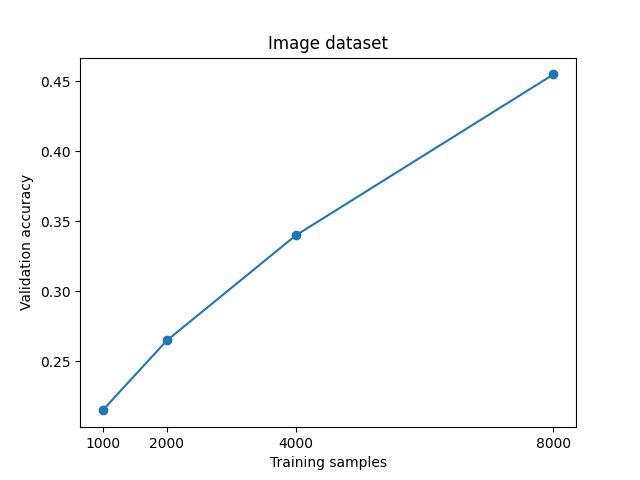

In [4]:
knn_result_dir = project_root / "results" / "knn"
knn_result_dir.mkdir(parents=True, exist_ok=True)
plt.figure()
plt.plot(image_summary["training_samples"], image_summary["validation_accuracy"], marker="o")
plt.xlabel("Training samples")
plt.ylabel("Validation accuracy")
plt.title("Image dataset")
plt.xticks(training_sizes)
plt.savefig(knn_result_dir / "knn_v6_image_accuracy.png")
plt.show()


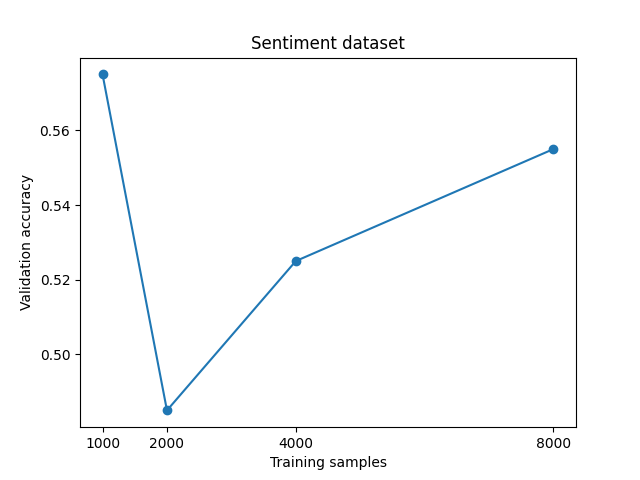

In [5]:
knn_result_dir = project_root / "results" / "knn"
knn_result_dir.mkdir(parents=True, exist_ok=True)
plt.figure()
plt.plot(sentiment_summary["training_samples"], sentiment_summary["validation_accuracy"], marker="o")
plt.xlabel("Training samples")
plt.ylabel("Validation accuracy")
plt.title("Sentiment dataset")
plt.xticks(training_sizes)
plt.savefig(knn_result_dir / "knn_v6_sentiment_accuracy.png")
plt.show()


Finally, I compared the results to see which training size worked best for each dataset.

In [6]:
print(f"Image:     {image_best_size} training samples, k={image_k}, accuracy={image_best_accuracy:.2%}")
print(f"Sentiment: {sentiment_best_size} training samples, k={sentiment_k}, accuracy={sentiment_best_accuracy:.2%}")


Image:     8000 training samples, k=1, accuracy=45.50%
Sentiment: 1000 training samples, k=3, accuracy=57.50%


I used the best training size for each dataset to predict the test labels.

In [7]:
image_clf = KNNClassifier(
    k=image_k, distance_fn=euclidean_distance, voting_method="majority"
)
image_clf.fit(image_X_train[:image_best_size], image_y_train[:image_best_size])
start = perf_counter()
image_test_predictions = image_clf.predict(image_X_test)
print(f"Image: predicted {len(image_test_predictions)} test labels in {perf_counter() - start:.2f} s")


Image: predicted 5000 test labels in 299.24 s


In [8]:
sentiment_clf = KNNClassifier(
    k=sentiment_k, distance_fn=euclidean_distance, voting_method="majority"
)
sentiment_clf.fit(sentiment_X_train[:sentiment_best_size], sentiment_y_train[:sentiment_best_size])
start = perf_counter()
sentiment_test_predictions = sentiment_clf.predict(sentiment_X_test)
print(f"Sentiment: predicted {len(sentiment_test_predictions)} test labels in {perf_counter() - start:.2f} s")


Sentiment: predicted 5000 test labels in 31.59 s


In [9]:
image_predictions = pd.DataFrame({"id": image_test_ids, "label": image_test_predictions})
sentiment_predictions = pd.DataFrame({"id": sentiment_test_ids, "label": sentiment_test_predictions})
assert len(image_predictions) == 5000 and len(sentiment_predictions) == 5000
assert image_predictions["label"].between(0, 49).all()
assert sentiment_predictions["label"].between(0, 2).all()

predictions = pd.concat([image_predictions, sentiment_predictions], ignore_index=True)
sample_submission = pd.read_csv(project_root / "data" / "raw" / "sample_submission.csv")
assert len(predictions) == 10000 and len(sample_submission) == 10000
assert predictions["id"].is_unique and sample_submission["id"].is_unique
assert set(predictions["id"]) == set(sample_submission["id"])

# A left merge keeps the sample submission's ID order.
submission = sample_submission[["id"]].merge(predictions, on="id", how="left", sort=False)
assert submission.columns.tolist() == ["id", "label"]
assert submission["id"].tolist() == sample_submission["id"].tolist()
assert not submission.isna().any().any()
assert pd.api.types.is_integer_dtype(submission["label"])

submission_dir = project_root / "submission" / "knn"
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / "submission_v6_knn.csv"
submission.to_csv(submission_path, index=False)
saved_submission = pd.read_csv(submission_path)
assert pd.api.types.is_integer_dtype(saved_submission["label"])
pd.testing.assert_frame_equal(saved_submission, submission, check_dtype=False)
print("Saved and checked 10000 predictions in", submission_path)

v2_submission = pd.read_csv(submission_dir / "submission_v2_knn.csv")
assert saved_submission["id"].tolist() == v2_submission["id"].tolist()
changed = saved_submission["label"] != v2_submission["label"]
changed_predictions = int(changed.sum())
changed_image_predictions = int((changed & saved_submission["id"].isin(image_test_ids)).sum())
changed_sentiment_predictions = int((changed & saved_submission["id"].isin(sentiment_test_ids)).sum())
assert changed_predictions == changed_image_predictions + changed_sentiment_predictions
print(f"Identical predictions to V2: {changed_predictions == 0}")
print(f"Changed predictions compared with V2: {changed_predictions}")
print(f"Changed image predictions: {changed_image_predictions}")
print(f"Changed sentiment predictions: {changed_sentiment_predictions}")
if image_best_size == 1000 and sentiment_best_size == 1000:
    pd.testing.assert_frame_equal(saved_submission, v2_submission, check_dtype=False)


Saved and checked 10000 predictions in C:\Users\user\OneDrive\Documentos\Fall2026\COMP472\team_project\COMP472\submission\knn\submission_v6_knn.csv
Identical predictions to V2: False
Changed predictions compared with V2: 3823
Changed image predictions: 3823
Changed sentiment predictions: 0


In [10]:
tracker_path = knn_result_dir / "kaggle_scores.csv"
tracker = pd.read_csv(tracker_path, dtype=str, keep_default_na=False)
assert tracker["version"].is_unique
v6_row = {
    "version": "V6",
    "image_validation_accuracy": image_best_accuracy,
    "sentiment_validation_accuracy": sentiment_best_accuracy,
    "kaggle_public_score": "",
    "submitted_to_kaggle": False,
    "submission_filename": submission_path.name,
    "notes": f"Tested 1000, 2000, 4000, 8000 training samples; selected image: {image_best_size}; sentiment: {sentiment_best_size}.",
}
matching = tracker["version"] == "V6"
if matching.any():
    # Preserve any recorded Kaggle score and status on reruns.
    for column in ("image_validation_accuracy", "sentiment_validation_accuracy", "submission_filename", "notes"):
        tracker.loc[matching, column] = v6_row[column]
else:
    tracker = pd.concat([tracker, pd.DataFrame([v6_row])], ignore_index=True)
assert tracker["version"].is_unique
tracker.to_csv(tracker_path, index=False)
print(tracker.to_string(index=False))


version image_validation_accuracy sentiment_validation_accuracy kaggle_public_score submitted_to_kaggle   submission_filename                                                                                                notes
     V1                      0.21                         0.575                                   False                                                                                k=3 and 1,000 training samples per dataset.
     V2                     0.215                         0.575               0.329                True submission_v2_knn.csv                                             Tested k=1, 3, 5, 10, 20; best image k=1, sentiment k=3.
     V3                     0.215                         0.575                                   False submission_v3_knn.csv      Compared Euclidean, Manhattan, Minkowski p=3; best image: Euclidean; best sentiment: Euclidean.
     V4                     0.215                         0.575                             